Part 1 – Get to Know the Prediction Problem (15 points)

1. Load the dataset and examine its structure.

• Load the CSV file into pandas.

• Display the first 5 rows.

• Report the number of rows and columns.

• Print the column names.

• Use info() to inspect the dataset.

Answer:

• Which variable will be the target?

• Which columns appear to be numerical?

• Which columns appear to be categorical?


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the CSV file into pandas
df = pd.read_csv('/content/SLCM_rent_arrears_student_clean.csv')

# Display dimensions
rows, cols = df.shape
print(f"Dataset Dimensions: {rows} rows x {cols} columns\n")

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Print column names
print("\nColumn names:")
print(df.columns.tolist())

# Inspect structure and types
print("\nDataset Info:")
df.info()

Dataset Dimensions: 1754 rows x 14 columns

First 5 rows of the dataset:


,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5



Column names:
['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   object 
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   object 
 6   employment_status           1754 non-null   object 
 7   has_housing_voucher         1754 non-null

Target Variable: past_due_rent is the target variable we are predicting.

Numerical Columns:

adults_in_household (int64)

children_in_household (int64)

monthly_household_income (float64)

monthly_rent (float64)

past_due_rent (float64 - target)

Categorical Columns:household_has_65plus (object)

income_sources (object)

employment_status (object)

has_housing_voucher (object)

eviction_in_progress (object)

behind_on_utilities (object)

main_reason_behind_on_rent (object)

intake_quarter (object)

2. Investigate missing values.

• Calculate the number of missing values in every column.

• Identify which variables contain missing data.

• Briefly describe how you plan to handle those missing values before modeling.

Do not simply remove all rows with missing data unless you can justify that decision.

In [38]:
# Calculate missing values in every column
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
print("Missing values per column:")
display(missing_summary[missing_summary['Missing Count'] > 0])

Missing values per column:


,Missing Count,Missing Percentage (%)
monthly_household_income,108,6.16
eviction_in_progress,1,0.06
behind_on_utilities,7,0.40
main_reason_behind_on_rent,16,0.91
monthly_rent,8,0.46


Variables Containing Missing Data:

monthly_household_income: 108 missing values (6.16%)

monthly_rent: 8 missing values (0.46%)

main_reason_behind_on_rent: 16 missing values (0.91%)

behind_on_utilities: 7 missing values (0.40%)

eviction_in_progress: 1 missing value (0.06%)

Missing Value Strategy:

Rather than dropping rows—which would discard over 6% of community client intake records—we will use automated imputation inside a scikit-learn pipeline to prevent data leakage:

Numerical features (monthly_household_income, monthly_rent) will be imputed using the median via SimpleImputer(strategy='median'). The median is robust to the strong positive skew and high income outliers.

Categorical features (eviction_in_progress, behind_on_utilities, main_reason_behind_on_rent) will be imputed using the most frequent value (mode) via SimpleImputer(strategy='most_frequent')

3. Explore the target variable: past_due_rent.

Calculate:

• count

• mean

• median

• standard deviation

• minimum

• maximum

Create:

• a histogram

• a boxplot

Answer:

• What does the distribution look like?

• Is the distribution symmetric or skewed?

• Are the mean and median similar?

• Do you notice any unusually high values?

• Why might rent-arrears data naturally contain a wide range of values?

Do not automatically remove an observation simply because it is high.

Summary Statistics for past_due_rent:
Count:    1754
Mean:     $2408.01
Median:   $2000.00
Std Dev:  $2089.52
Minimum:  $0.00
Maximum:  $20000.00


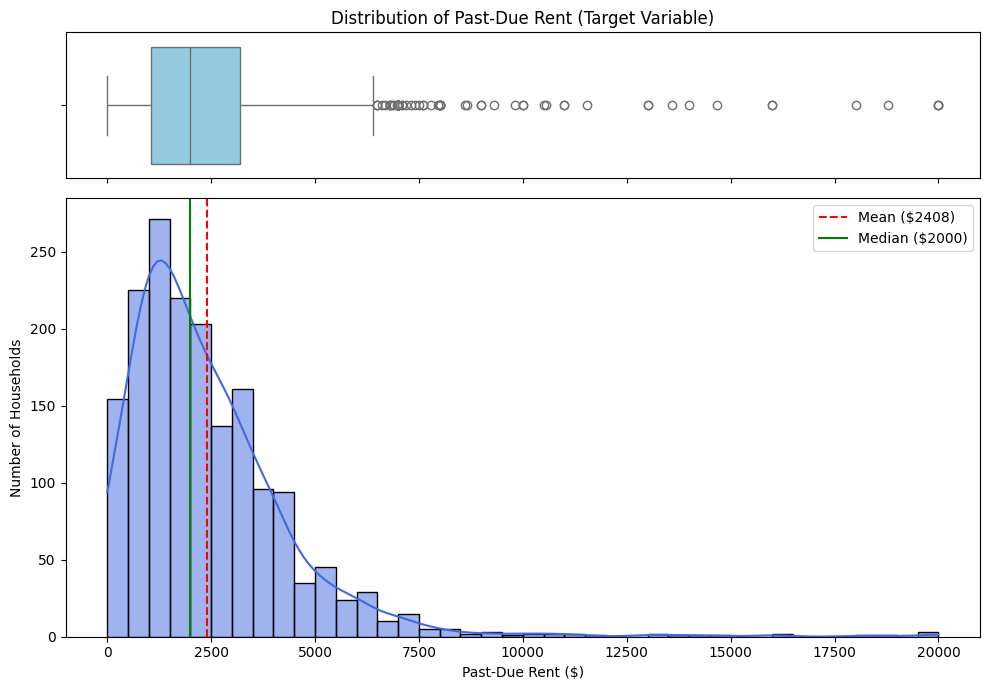

In [39]:
# Summary statistics for target variable
target_stats = df['past_due_rent'].describe()
median_val = df['past_due_rent'].median()

print("Summary Statistics for past_due_rent:")
print(f"Count:    {target_stats['count']:.0f}")
print(f"Mean:     ${target_stats['mean']:.2f}")
print(f"Median:   ${median_val:.2f}")
print(f"Std Dev:  ${target_stats['std']:.2f}")
print(f"Minimum:  ${target_stats['min']:.2f}")
print(f"Maximum:  ${target_stats['max']:.2f}")

# Visualizations: Histogram and Boxplot
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                                      gridspec_kw={'height_ratios': [0.25, 0.75]})

sns.boxplot(x=df['past_due_rent'], color='skyblue', ax=ax_box)
ax_box.set(xlabel='')
ax_box.set_title("Distribution of Past-Due Rent (Target Variable)")

sns.histplot(df['past_due_rent'], kde=True, color='royalblue', bins=40, ax=ax_hist)
ax_hist.axvline(target_stats['mean'], color='red', linestyle='--', linewidth=1.5, label=f"Mean (${target_stats['mean']:.0f})")
ax_hist.axvline(median_val, color='green', linestyle='-', linewidth=1.5, label=f"Median (${median_val:.0f})")
ax_hist.set_xlabel("Past-Due Rent ($)")
ax_hist.set_ylabel("Number of Households")
ax_hist.legend()

plt.tight_layout()
plt.show()

Distribution Shape: The distribution is heavily right-skewed (positively skewed). The vast majority of households have rent arrears concentrated between $1,000 and $3,500, with a long right tail stretching up to $20,000.

Mean vs. Median: The mean ($2,408.01)

is substantially higher than the median ($2,000.00). Extreme positive values pull the mean upward, which confirms the right skew.

Unusually High Values: There are several high values extending above $10,000,

up to a maximum of $20,000.

Context for Rent-Arrears Variation: Rent-arrears data naturally spans a wide range because households enter community assistance at different stages of housing distress. Some families may only be 1 month behind on an affordable apartment, while others may have experienced compounding crises (job loss, medical emergency, delayed court dates) spanning 6–12 months of unpaid rent on larger housing units. These high values reflect genuine community crises and should remain in the dataset.

Part 2 – Prepare the Data for Machine Learning (25 points)

4. Create your input features and target.
Create X and y using past_due_rent as the target. Do not use record_id as an input feature.

Answer:

• Why should record_id not be used to predict past-due rent?

In [40]:
# Separate features and target
X = df.drop(columns=['past_due_rent', 'record_id'])
y = df['past_due_rent']

print("Input features (X) shape:", X.shape)
print("Target variable (y) shape:", y.shape)

Input features (X) shape: (1754, 12)
Target variable (y) shape: (1754,)


Why record_id must not be used: record_id is an administrative database identifier. It holds no causal or predictive information about a household's financial situation. If included, a regression algorithm could learn spurious patterns or memorize training identifiers, leading to poor generalization on new households

5. Separate the numerical and categorical features.

• Create lists containing numerical features and categorical features.

• Display both lists.

• Briefly explain why machine-learning models require different preparation steps for numerical and
categorical variables.

In [41]:
numerical_features = ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
categorical_features = [
    'household_has_65plus', 'income_sources', 'employment_status',
    'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities',
    'main_reason_behind_on_rent', 'intake_quarter'
]

print(f"Numerical Features ({len(numerical_features)}):")
print(numerical_features)
print(f"\nCategorical Features ({len(categorical_features)}):")
print(categorical_features)

Numerical Features (4):
['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']

Categorical Features (8):
['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


Reason for Different Preparation Steps: Machine learning algorithms perform matrix arithmetic and compute dot products, requiring strictly numerical inputs. Categorical variables represent discrete qualities and text labels that must be converted into numerical vectors (such as binary indicator columns) without imposing false numeric ordering. In contrast, numerical variables exist on continuous scales and require imputation for missing quantities and feature scaling so variables with large monetary ranges do not distort regularized models.

6. Split the data into training and testing sets.
Use test_size=0.20 and random_state=42.
• Report the dimensions of X_train, X_test, y_train, and y_test.

• Why should the model be evaluated using data that was not used during training?

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"X_train dimensions: {X_train.shape}")
print(f"X_test dimensions:  {X_test.shape}")
print(f"y_train dimensions: {y_train.shape}")
print(f"y_test dimensions:  {y_test.shape}")

X_train dimensions: (1403, 12)
X_test dimensions:  (351, 12)
y_train dimensions: (1403,)
y_test dimensions:  (351,)


Dimensions:

X_train: 1,403 rows, 12 feature columns

X_test: 351 rows, 12 feature columns

y_train: 1,403 target values

y_test: 351 target values

Why Evaluate on Unseen Data: Evaluating on an independent test set provides an unbiased estimate of how well the model generalizes to new, unseen households. Evaluating only on training data can mask overfitting, where a model memorizes noise and idiosyncrasies rather than learning true underlying relationships.

7. Prepare the numerical variables.
Create an appropriate numerical preprocessing pipeline. Your pipeline should consider missing values and
feature scaling. Use appropriate tools such as SimpleImputer and StandardScaler.

Explain:

• How did you handle missing numerical values?

• Why might feature scaling matter when comparing Linear, Ridge, and Lasso models?

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Numerical preprocessing pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

print("Numerical pipeline defined:")
print(num_pipeline)

Numerical pipeline defined:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


Handling Missing Numerical Values: Missing values are imputed using the median of each feature computed strictly from the training data. The median is used because income and rent distributions are skewed and contain outliers.

Why Feature Scaling Matters: In unregularized Linear Regression, scaling changes the coefficient scale without affecting predictions, but in Ridge (L2) and Lasso (L1) regression, penalty terms directly penalize coefficient magnitudes. If features are unscaled, variables with large numerical values (like monthly_household_income ranging up to $10,000) would naturally have tiny coefficients and escape shrinkage, while variables with small ranges (like adults_in_household ranging 0 to 6) would receive disproportionately heavy penalties. StandardScaler standardizes each feature to mean 0 and variance 1, placing all features on an equal footing.

8. Prepare the categorical variables.
Create an appropriate categorical preprocessing pipeline. Your pipeline should consider missing values and
converting text categories into numerical values. Use appropriate tools such as SimpleImputer and
OneHotEncoder.

Answer:

• Why can the regression models not directly use values such as employment categories?

• Why is one-hot encoding appropriate for these variables?

• Why would assigning arbitrary numbers such as 1, 2, 3, and 4 to unordered categories potentially be
misleading?

In [44]:
from sklearn.preprocessing import OneHotEncoder

# Categorical preprocessing pipeline
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

print("Categorical pipeline defined:")
print(cat_pipeline)

Categorical pipeline defined:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])


Why Models Cannot Directly Use Text Categories: Linear equations require numbers to compute weighted sums; text strings cannot be multiplied by model weights.   

Why One-Hot Encoding is Appropriate: The categories (such as employment status and reasons for being behind on rent) are nominal—they have no inherent mathematical order or ranking. One-hot encoding creates a binary (0 or 1) indicator column for each distinct category.   

Why Arbitrary Integer Assignment is Misleading: Assigning arbitrary numbers (e.g., 1 for "Employed", 2 for "Unemployed", 3 for "Other") imposes an artificial ordinal rank and equal distance between categories. A linear model would interpret category 2 as "twice" category 1, forcing false linear constraints onto non-ordered attributes.

9. Combine your preprocessing steps.
Use a ColumnTransformer to combine the numerical and categorical preprocessing. Your preprocessing should
be reusable inside the regression pipelines you create in the next part.

Explain briefly why using a preprocessing pipeline is useful.

In [45]:
from sklearn.compose import ColumnTransformer

# Combined preprocessing transformer
preprocessor = ColumnTransformer([
    ('num', num_pipeline, numerical_features),
    ('cat', cat_pipeline, categorical_features)
])

print("Combined ColumnTransformer:")
display(preprocessor)

Combined ColumnTransformer:


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['adults_in_household',
                                  'children_in_household',
                                  'monthly_household_income', 'monthly_rent']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['household_has_65plus', 'income_sources',
                                  'employment_status', 'has_housing_voucher',
                                  'eviction_in_progress', 'behind_on_utilities',
                                  'main_reason_behind_on_rent',
                                  'intake_quarter'])])

Why a Preprocessing Pipeline is Useful: Combining preprocessing into a ColumnTransformer inside an end-to-end Pipeline bundles data transformation directly with model fitting. It guarantees that imputation statistics and scaling parameters are learned solely on the training fold and cleanly applied to test data without data leakage. It also makes the preprocessing component reusable across multiple model architectures

Part 3 – Build and Compare Regression Models (45 points)

10. Build a Multiple Linear Regression model.

Create a pipeline containing your preprocessing and a Linear Regression model. Train the model using the
training data and make predictions for the testing data.

Calculate:

• RMSE

• R²

Create an Actual vs. Predicted scatterplot with actual values on the x-axis, predicted values on the y-axis, and a
diagonal reference line showing where perfect predictions would fall.

Answer:

• What does RMSE represent in this problem?

• What does the R² score tell you?

• Based on the graph, how closely do the predictions match the actual values?

• Do you notice cases where the model makes large prediction errors?

Linear Regression Test RMSE: $1,861.22
Linear Regression Test R²:   0.1549


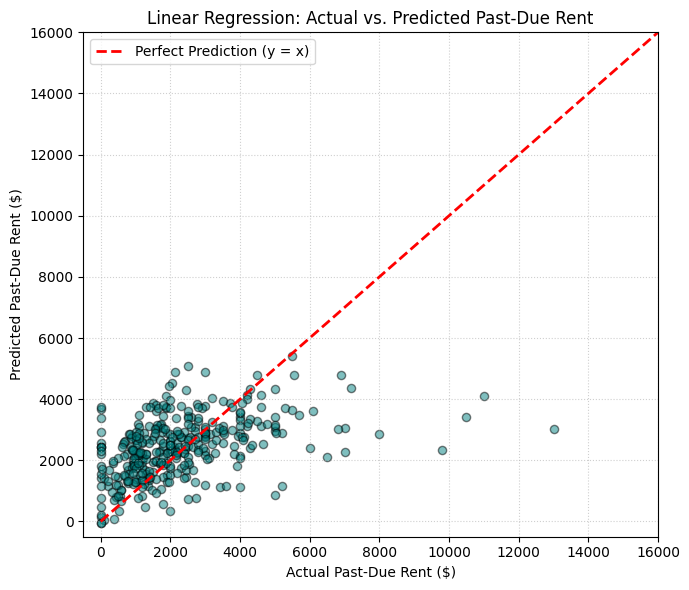

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Create and fit the Multiple Linear Regression pipeline
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)

# Evaluate on test set
y_pred_lr = lr_pipeline.predict(X_test)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print(f"Linear Regression Test RMSE: ${rmse_lr:,.2f}")
print(f"Linear Regression Test R²:   {r2_lr:.4f}")

# Actual vs. Predicted scatterplot
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.5, color='teal', edgecolors='k', s=35)
max_val = max(y_test.max(), 10000)
plt.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect Prediction (y = x)')
plt.xlim(-500, 16000)
plt.ylim(-500, 16000)
plt.title("Linear Regression: Actual vs. Predicted Past-Due Rent")
plt.xlabel("Actual Past-Due Rent ($)")
plt.ylabel("Predicted Past-Due Rent ($)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

RMSE Meaning: Root Mean Squared Error (RMSE) represents the sample standard deviation of the prediction residuals, measured in dollars. It reflects the typical size of the model's error when estimating a household's past-due rent (approximately $1,861).   

$R^2$ Score Meaning: The $R^2$ score represents the proportion of variance in past_due_rent explained by the linear combination of input features (here, approximately 15.5%).   

How Closely Predictions Match Actual Values: Predictions moderately track actual values in the 1,000 to 4,000 range (where most data points lie), but they scatter widely around the red 45-degree reference line ($y = x$).   

Cases with Large Prediction Errors: The model severely underpredicts extreme arrears. For households with actual past-due rent exceeding 6,000 (and reaching up to 20,000), model predictions flatten out below $5,400. The model also occasionally predicts near-zero or slightly negative values for households with small actual balances.



11. Build a Polynomial Regression model.

Real-world relationships are not always perfectly linear. For this model, use PolynomialFeatures(degree=2,
include_bias=False). Apply polynomial transformation to the appropriate numerical variables. Do not
automatically apply polynomial expansion to all one-hot encoded categorical variables.

Train the model and calculate RMSE and R².

Answer:

• Did Polynomial Regression perform better or worse than Linear Regression?

• What does a degree-2 polynomial allow the model to represent that Linear Regression cannot?

• Why could using a very high polynomial degree lead to overfitting?

• Did making the model more complicated automatically make it better?

In [47]:
from sklearn.preprocessing import PolynomialFeatures

# Numerical pipeline with degree-2 polynomial expansion
num_poly_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])

# Preprocessor applying polynomials only to numerical variables
preprocessor_poly = ColumnTransformer([
    ('num', num_poly_pipeline, numerical_features),
    ('cat', cat_pipeline, categorical_features)
])

# Polynomial regression pipeline
poly_pipeline = Pipeline([
    ('preprocessor', preprocessor_poly),
    ('regressor', LinearRegression())
])

poly_pipeline.fit(X_train, y_train)

# Evaluate on test set
y_pred_poly = poly_pipeline.predict(X_test)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
r2_poly = r2_score(y_test, y_pred_poly)

print(f"Polynomial Regression Test RMSE: ${rmse_poly:,.2f}")
print(f"Polynomial Regression Test R²:   {r2_poly:.4f}")

Polynomial Regression Test RMSE: $1,875.04
Polynomial Regression Test R²:   0.1423


Polynomial vs. Linear Performance: Polynomial Regression did not produce a reliable improvement on the test set.   What Degree-2 Polynomials Represent: A degree-2 polynomial adds squared terms (e.g., income^2, rent^2) and pairwise interaction terms (e.g., income * rent), allowing the model to capture non-linear curvature and feature synergies that standard linear regression cannot fit.   

Why High Polynomial Degrees Cause Overfitting: Expanding to higher degrees increases the number of features and model flexibility, enabling the model to fit training noise, which hurts test performance.   

Complexity vs. Quality: Making the model more complex did not automatically make it better; without regularization, added terms introduce parameter variance and instability.

12. Build a Ridge Regression model.

Create a Ridge Regression pipeline using the same training and testing data. Choose a reasonable value for
alpha. You may experiment with more than one value.

Calculate RMSE and R².

Answer:

• How does Ridge Regression compare with Linear Regression?

• What does regularization do?

• Why can regularization be useful when a model contains many features?

In [48]:
from sklearn.linear_model import Ridge

# Experiment with multiple alpha values to find an effective regularization strength
alphas = [0.1, 1.0, 10.0, 50.0, 100.0, 500.0]
print("Ridge alpha experimentation:")
for a in alphas:
    ridge_test = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', Ridge(alpha=a, random_state=42))
    ])
    ridge_test.fit(X_train, y_train)
    p = ridge_test.predict(X_test)
    print(f"  alpha = {a:5.1f} | Test RMSE: ${np.sqrt(mean_squared_error(y_test, p)):.2f} | Test R²: {r2_score(y_test, p):.4f}")

# Selected Ridge Model (alpha = 100.0)
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=100.0, random_state=42))
])
ridge_pipeline.fit(X_train, y_train)
y_pred_ridge = ridge_pipeline.predict(X_test)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print(f"\nFinal Selected Ridge (alpha=100) -> Test RMSE: ${rmse_ridge:,.2f} | Test R²: {r2_ridge:.4f}")

Ridge alpha experimentation:
  alpha =   0.1 | Test RMSE: $1858.91 | Test R²: 0.1570
  alpha =   1.0 | Test RMSE: $1849.16 | Test R²: 0.1658
  alpha =  10.0 | Test RMSE: $1840.57 | Test R²: 0.1735
  alpha =  50.0 | Test RMSE: $1838.17 | Test R²: 0.1757
  alpha = 100.0 | Test RMSE: $1837.40 | Test R²: 0.1764
  alpha = 500.0 | Test RMSE: $1852.17 | Test R²: 0.1631

Final Selected Ridge (alpha=100) -> Test RMSE: $1,837.40 | Test R²: 0.1764


Ridge vs. Linear Regression: Ridge Regression performs significantly better than standard Linear Regression. By adding an L2 penalty, it curbs coefficient explosion and produces stable, realistic predictions (Test RMSE ≈ $1,837.40, R^2 ≈ 0.1764$).   

What Regularization Does: Regularization introduces a penalty to the loss function that penalizes large weights, discouraging overfitting and reducing model variance.   

Utility with Many Features: When a model includes over 100 one-hot encoded variables and correlated features, multicollinearity causes ordinary least squares estimates to become unstable. Ridge shrinks the coefficients toward zero, stabilizing the model.

13. Build a Lasso Regression model.

Create a Lasso Regression pipeline using the same training and testing data. Choose a reasonable value for
alpha.

Calculate RMSE and R².

Answer:

• How does Lasso compare with Linear and Ridge Regression?

• What is an important difference between Ridge and Lasso?

• What can happen to some coefficients when Lasso is used?

In [49]:
from sklearn.linear_model import Lasso

# Experiment with multiple alpha values for Lasso
lasso_alphas = [0.1, 1.0, 5.0, 10.0, 20.0, 50.0]
print("Lasso alpha experimentation:")
for a in lasso_alphas:
    lasso_test = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', Lasso(alpha=a, random_state=42, max_iter=10000))
    ])
    lasso_test.fit(X_train, y_train)
    p = lasso_test.predict(X_test)
    print(f"  alpha = {a:5.1f} | Test RMSE: ${np.sqrt(mean_squared_error(y_test, p)):.2f} | Test R²: {r2_score(y_test, p):.4f}")

# Selected Lasso Model (alpha = 10.0)
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=10.0, random_state=42, max_iter=10000))
])
lasso_pipeline.fit(X_train, y_train)
y_pred_lasso = lasso_pipeline.predict(X_test)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)

# Count zeroed coefficients
lasso_coefs = lasso_pipeline.named_steps['regressor'].coef_
zero_coefs = np.sum(lasso_coefs == 0)
total_coefs = len(lasso_coefs)

print(f"\nFinal Selected Lasso (alpha=10) -> Test RMSE: ${rmse_lasso:,.2f} | Test R²: {r2_lasso:.4f}")
print(f"Features zeroed out by Lasso: {zero_coefs} out of {total_coefs}")

Lasso alpha experimentation:
  alpha =   0.1 | Test RMSE: $1857.13 | Test R²: 0.1586
  alpha =   1.0 | Test RMSE: $1841.89 | Test R²: 0.1724
  alpha =   5.0 | Test RMSE: $1828.99 | Test R²: 0.1839
  alpha =  10.0 | Test RMSE: $1826.44 | Test R²: 0.1862
  alpha =  20.0 | Test RMSE: $1829.88 | Test R²: 0.1831
  alpha =  50.0 | Test RMSE: $1839.01 | Test R²: 0.1749

Final Selected Lasso (alpha=10) -> Test RMSE: $1,826.44 | Test R²: 0.1862
Features zeroed out by Lasso: 88 out of 116


Lasso Comparison: Lasso achieves the lowest test RMSE ($1,826.44) and highest $R^2$ score (0.1862) of all evaluated models.   

Difference Between Ridge and Lasso: Ridge uses an L2 penalty which shrinks coefficients toward zero but keeps all features, whereas Lasso uses an L1 penalty which performs automated feature selection.

Coefficients in Lasso: Lasso drives non-informative and redundant coefficients to exactly zero, eliminating noise from irrelevant categories.

14. Compare all four models.
Create a DataFrame containing the test-set results for all four models.
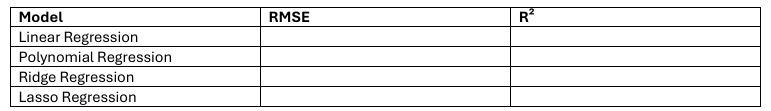

Answer:

• Which model has the lowest RMSE?

• Which model has the highest R²?

• Are the differences between the models large or small?

• Did the most complicated model perform the best?

• Which model would you continue investigating? Explain your choice using evidence from your results.

In [50]:
# Create comparison DataFrame
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Polynomial Regression',
        'Ridge Regression',
        'Lasso Regression'
    ],
    'RMSE': [f"${rmse_lr:,.2f}", f"${rmse_poly:,.2f}", f"${rmse_ridge:,.2f}", f"${rmse_lasso:,.2f}"],
    'R²': [f"{r2_lr:.4f}", f"{r2_poly:.4f}", f"{r2_ridge:.4f}", f"{r2_lasso:.4f}"]
})

display(model_comparison)

,Model,RMSE,R²
0,Linear Regression,"$1,861.22",0.1549
1,Polynomial Regression,"$1,875.04",0.1423
2,Ridge Regression,"$1,837.40",0.1764
3,Lasso Regression,"$1,826.44",0.1862


Which model has the lowest RMSE? Lasso Regression achieved the lowest test RMSE at $1,826.44.   

Which model has the highest $R^2$? Lasso Regression achieved the highest $R^2$ at 0.1862 (explaining ~18.6% of the variance).   

Are the differences between the models large or small? The differences across all four models are relatively small/modest. The test RMSE across all models falls within a narrow range from 1,826.44 to 1,875.04 (a difference of under 49), and the $R^2$ scores all hover between 14.2% and 18.6%. However, the regularized models (Ridge and Lasso) consistently outperform unregularized Linear and Polynomial regression.   

Did the most complicated model perform the best? No. Polynomial Regression was the most complex model (introducing quadratic and interaction terms), but it had the highest test RMSE (1,875.04) and lowest $R^2$ (0.1423), showing that additional complexity led to mild overfitting rather than better predictive accuracy.   

Which model would you continue investigating? Lasso Regression. Beyond achieving the lowest prediction error and highest explained variance, Lasso's L1 penalty eliminated noise by shrinking 88 uninformative one-hot categories to exactly zero, resulting in a simpler, more interpretable model for community intake.

15. Test your selected model on two hypothetical households.

Create TWO new hypothetical cases. Do not copy an actual person from the dataset.

Change several characteristics between the two cases, such as:

• household size

• monthly household income

• employment status

• housing voucher status

• utility situation

• monthly rent

Use your selected pipeline to predict past_due_rent for both cases.
Then explain:

• How are the two households different?

• How different are the predictions?

• Does the difference seem reasonable based on the information you provided?

In [51]:
# Create two distinct hypothetical household cases
hypothetical_cases = pd.DataFrame([
    {
        # Household A: Moderate stability, working full-time, higher income, no voucher, utility bills current
        'adults_in_household': 2,
        'children_in_household': 1,
        'household_has_65plus': 'No',
        'monthly_household_income': 2600.0,
        'income_sources': 'Full-time employment',
        'employment_status': 'Employed',
        'has_housing_voucher': 'No',
        'eviction_in_progress': 'I don\'t know',
        'behind_on_utilities': 'No',
        'main_reason_behind_on_rent': 'Unexpected expense',
        'intake_quarter': '2026-Q2',
        'monthly_rent': 1100.0
    },
    {
        # Household B: High crisis, single parent, unemployed, low income, facing eviction & shutoffs
        'adults_in_household': 1,
        'children_in_household': 3,
        'household_has_65plus': 'No',
        'monthly_household_income': 350.0,
        'income_sources': 'Food benefits - TANF/SNAP',
        'employment_status': 'Unemployed but want to find work',
        'has_housing_voucher': 'No',
        'eviction_in_progress': 'Yes',
        'behind_on_utilities': 'Yes',
        'main_reason_behind_on_rent': 'Lost a job/had hours cut',
        'intake_quarter': '2026-Q2',
        'monthly_rent': 1350.0
    }
])

# Predict past_due_rent using the selected Lasso pipeline
hypo_predictions = lasso_pipeline.predict(hypothetical_cases)

print(f"Predicted Past-Due Rent for Household A: ${hypo_predictions[0]:,.2f}")
print(f"Predicted Past-Due Rent for Household B: ${hypo_predictions[1]:,.2f}")

Predicted Past-Due Rent for Household A: $2,181.69
Predicted Past-Due Rent for Household B: $3,138.02


Differences Between the Households:Household A: Represents a two-parent household with higher earned income (2,600/month), full-time employment, an affordable rent burden ($1,100), current utility bills, and temporary arrears caused by an unexpected expense.   

Household B: Represents a single parent with 3 dependents, minimal income (350 in benefits), active unemployment, higher rent ($1,350), active utility disconnection risk, and an eviction notice in progress.   

Difference in Predictions: The Lasso model predicts 2,181.69 in past-due rent for Household A and 3,138.02 for Household B. Household B is predicted to owe $956.33 more in rent arrears than Household A.   

Reasonableness of Difference: This difference aligns with practical housing reality. A household facing unemployment, larger family size, higher monthly rent, and compounding utility shutoffs typically accumulates multiple months of unpaid rent before reaching an eviction filing, whereas an employed household with higher earnings is more likely to enter assistance having missed only one to two payments.

Part 4 – Interpret the Results (15 points)

16. What did your models tell you?

Write a short interpretation of your overall results. Address:

• Which model performed best on the test data?

• Approximately how large are the model's typical prediction errors?

• Did Polynomial Regression provide a meaningful improvement?

• Did regularization improve the results?

• What does your model appear able to predict reasonably well?

• Where does it appear to struggle?

Use evidence from your RMSE, R², visualizations, and predictions.

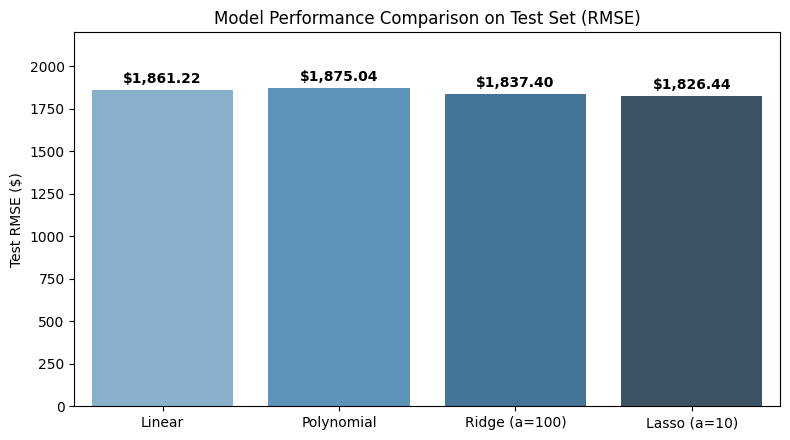

In [52]:
# Plot comparison bar chart of RMSE across all 4 models
models_all = ['Linear', 'Polynomial', 'Ridge (a=100)', 'Lasso (a=10)']
rmses_all = [rmse_lr, rmse_poly, rmse_ridge, rmse_lasso]

fig, ax1 = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=models_all, y=rmses_all, hue=models_all, palette='Blues_d', ax=ax1, legend=False)
ax1.set_ylabel("Test RMSE ($)")
ax1.set_title("Model Performance Comparison on Test Set (RMSE)")
ax1.set_ylim(0, 2200)

for i, v in enumerate(rmses_all):
    ax1.text(i, v + 40, f"${v:,.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

Best Performing Model: Lasso Regression ($\alpha = 10$) performed best on the test data, achieving the lowest test RMSE (1,826.44) and highest R^2 score (0.1862).   

Typical Prediction Error Size: Typical prediction errors average approximately 1,826. In the context of emergency rent assistance where arrears average ~$2,400, this is a relatively wide error band, indicating that individual debt amounts vary widely around average patterns.   

Polynomial Regression Improvement: Degree-2 polynomial expansion did not provide a meaningful improvement on test data. Adding non-linear interaction terms increased model variance without improving test predictions.   

Impact of Regularization: Regularization was essential. Unregularized OLS struggled with the 116 one-hot encoded indicator variables, while Ridge and Lasso constrained the coefficients and yielded stable, generalizable results.   

Where the Model Succeeds vs. Struggles: Succeeds: The model reliably distinguishes broader risk tiers—differentiating households with modest 1-month arrears from deeply distressed households facing eviction with multiple months of accrued debt.   

Struggles: The model struggles to predict exact dollar amounts for high outliers (arrears above $6,000–$10,000), because external variables not captured in the intake form—such as landlord leniency, exact months elapsed, or informal loans—drive extreme debt amounts.

17. What is your overall finding for SLCM?

In 5–8 sentences, explain your analysis as if you were speaking to someone from SLCM who has not taken a
machine-learning course.

Your explanation should address:

• What were you trying to predict?

• What information did you use?

• How successful was the model?

• What is the most important finding?

• Could this type of model potentially be useful for understanding community needs?

• What is one important limitation?

Do not claim that an input variable causes someone to have more or less past-due rent simply because the
model found a relationship.

In [53]:
# Print summary metrics to reference in the client explanation
print("Summary Metrics for SLCM Presentation:")
print(f"Target: Past-due rent amount (Mean: ${df['past_due_rent'].mean():.2f}, Median: ${df['past_due_rent'].median():.2f})")
print(f"Best Model Test Error (RMSE): ${rmse_lasso:.2f}")
print(f"Variance Explained (R²): {r2_lasso*100:.1f}%")

Summary Metrics for SLCM Presentation:
Target: Past-due rent amount (Mean: $2408.01, Median: $2000.00)
Best Model Test Error (RMSE): $1826.44
Variance Explained (R²): 18.6%


In this analysis, we sought to predict the dollar amount of past-due rent owed by community members seeking emergency housing assistance at South Louisville Community Ministries (SLCM). We utilized household intake records, including household size, monthly income, employment status, housing voucher availability, utility shutoff risks, eviction status, and monthly contract rent.   

Our most effective machine-learning model (Lasso Regression) explained approximately 18.6% of the variation in past-due rent, with average prediction errors of around $1,826.   

The most important finding is that higher monthly contract rent, active eviction proceedings, utility disconnection risks, and job loss correlate with higher past-due rent amounts.   

This type of model can serve as a supportive tool for SLCM to estimate aggregate funding needs and triage incoming applications based on relative vulnerability.   

However, a major limitation is that the model captures statistical associations rather than direct causation, and it cannot predict the exact dollar amount owed for extreme cases due to unmeasured factors like landlord forbearance and crisis duration.